In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import tldextract
from sklearn.model_selection import StratifiedGroupKFold
from urllib.parse import urlsplit
import os
import json


# Preperation of Dataset


In [19]:
file_path = "PhiUSIIL_Phishing_URL_Dataset.csv"
df_full = pd.read_csv(file_path, header=0)
df_full.head()

print(df_full.columns)


Index(['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP',
       'TLD', 'URLSimilarityIndex', 'CharContinuationRate',
       'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain',
       'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
       'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL',
       'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
       'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
       'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength',
       'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore',
       'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect',
       'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
       'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
       'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
       'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
       'NoOfEmptyRef', 'NoOf

In [20]:
#keep url related columns for EDA
url_features = ["URLLength", "Domain", "DomainLength", "IsDomainIP", "TLD", "NoOfSubDomain",
             "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL", "IsHTTPS"]
df = df_full[["URL"] + url_features + ["label"]].copy()

print(f"\nShape: {df.shape}")
print(f"\nHead: {df.head()}")
print(f"\nType: \n{df.dtypes}")


Shape: (235795, 12)

Head:                                   URL  URLLength                      Domain  \
0    https://www.southbankmosaics.com         31    www.southbankmosaics.com   
1            https://www.uni-mainz.de         23            www.uni-mainz.de   
2      https://www.voicefmradio.co.uk         29      www.voicefmradio.co.uk   
3         https://www.sfnmjournal.com         26         www.sfnmjournal.com   
4  https://www.rewildingargentina.org         33  www.rewildingargentina.org   

   DomainLength  IsDomainIP  TLD  NoOfSubDomain  LetterRatioInURL  \
0            24           0  com              1             0.581   
1            16           0   de              1             0.391   
2            22           0   uk              2             0.517   
3            19           0  com              1             0.500   
4            26           0  org              1             0.606   

   DegitRatioInURL  SpacialCharRatioInURL  IsHTTPS  label  
0              0

In [21]:
# check dataset features
print("URLLength == len(URL):", f"{(df['URL'].astype(str).str.len() == df['URLLength']).mean():.2%}")
print("Domain appears in URL:", np.mean([dm in u for dm, u in zip(df["Domain"], df["URL"])]))
print("IsHTTPS matches scheme:", (df["URL"].str.startswith("https") == df["IsHTTPS"].astype(bool)).mean())

URLLength == len(URL): 20.63%
Domain appears in URL: 1.0
IsHTTPS matches scheme: 0.9979092007888208


In [22]:
# recompute features (since ~80% of URLLength do not match)
L = df["URL"].str.len()
df["URLLength"] = L
df["LetterRatioInURL"] = df["URL"].str.count(r"[A-Za-z]") / L
df["DegitRatioInURL"] = df["URL"].str.count(r"\d") / L
df["SpacialCharRatioInURL"] = 1 - df["LetterRatioInURL"] - df["DegitRatioInURL"]
df["IsHTTPS"] = df["URL"].str.startswith("https://").astype(int)

# Data Cleaning

In [23]:
#check missing
print(df.isna().sum())

URL                      0
URLLength                0
Domain                   0
DomainLength             0
IsDomainIP               0
TLD                      0
NoOfSubDomain            0
LetterRatioInURL         0
DegitRatioInURL          0
SpacialCharRatioInURL    0
IsHTTPS                  0
label                    0
dtype: int64


In [24]:
# check end slash 
df["d"] = df["URL"].str.len() - df["URLLength"]
df["ends_slash"] = df["URL"].str.endswith("/")
print(pd.crosstab([df["label"], df["ends_slash"]], df["d"]))

d                      0
label ends_slash        
0     False        64132
      True         36813
1     False       134850


In [25]:
# only phishing urls have end slash --> remove end slash for all
df["URL"] = df["URL"].str.replace(r"/+$", "", regex=True)
print("Ends with '/':", df.groupby("label")["URL"].apply(lambda s: s.str.endswith("/").mean()))

Ends with '/': label
0    0.0
1    0.0
Name: URL, dtype: float64


In [26]:
#check empty and duplicates URLs
df["URL"] = df["URL"].astype(str).str.strip()

#invalid urls with whitespaces
edge_whitespace = (df["URL"] != df["URL"].str.strip()).sum()
df["URL"] = df["URL"].str.strip()
print("URLs with leading/trailing whitespace:", edge_whitespace)

inner_ws = df["URL"].str.contains(r"\s", regex=True)
print("URLs with internal whitespace:", inner_ws.sum())

print("Empty URLs:", df["URL"].eq("").sum())
print("Unique URLs:", df["URL"].nunique())
print("Duplicate URLs:", df.duplicated(subset="URL").sum())

URLs with leading/trailing whitespace: 0
URLs with internal whitespace: 0
Empty URLs: 0
Unique URLs: 234205
Duplicate URLs: 1590


In [27]:
#check if any labels are diff for any duplicates
duplicates = df[df.duplicated(subset="URL", keep=False)] \
                .sort_values("URL")
label_counts = duplicates.groupby("URL")["label"].nunique()

conflicting_urls = label_counts[label_counts > 1]

print("URLs with conflicting labels:", len(conflicting_urls))
print(conflicting_urls)

URLs with conflicting labels: 1
URL
https://www.education.gouv.fr    2
Name: label, dtype: int64


In [28]:
#drop duplicates
df = df[~df["URL"].isin(conflicting_urls.index)]
df = df.drop_duplicates(subset = "URL", keep = "first").reset_index(drop = True)
print("Rows after removing duplicates:", len(df))
print("Duplicate URLs remaining:", df.duplicated(subset="URL").sum())

Rows after removing duplicates: 234204
Duplicate URLs remaining: 0


In [29]:
#drop near-duplicate urls: 
# - http vs https
# - lowercase hostname
# - www vs www2 etc.
# - remove trailing /

def normalise(u: str) -> str:
    s = re.sub(r"^[A-Za-z][A-Za-z0-9+.\-]*://", "", u)
    m = re.match(r"([^/?#]*)(.*)", s)
    host, rest = m.group(1).lower(), m.group(2)
    host = re.sub(r"^www\d*\.", "", host)
    return host + rest

df["normalised"] = df["URL"].map(normalise)

# normalised urls wiht conflicting labels
g = df.groupby("normalised")["label"].nunique()
conflict_keys = g[g > 1].index
print("Normalised URLs with conflicting labels:", len(conflict_keys))


df = df[~df["normalised"].isin(conflict_keys)]
df = df.drop_duplicates(subset="normalised", keep="first").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))


Normalised URLs with conflicting labels: 42
Rows after removing duplicates: 231747


In [31]:
starts_https_www = df["URL"].str.lower().str.startswith("https://www.")

pd.crosstab(
    starts_https_www,
    df["label"],
    normalize="columns"
)


label,0,1
URL,,
False,0.978471,0.0
True,0.021529,1.0


Given that Label 0 represents legitamate URL and label 1 for phising url, only 2.15% of phising URL starts with https://www. This suggest that the prefix is a data colelction artifacr rather than a reliable indicator of whether the URL is malicious. A model can therefore achieve high performance by learning this simple prefix pattern instead of meaningful structural characteristics and it can be furthur exploited in adverserial experiments. Hence, it is dropped 

In [32]:
#removing https://www

def canonicalize_model_url(url):
    url = str(url).strip()

    #remove URI scheme
    url = re.sub(
        r"^[A-Za-z][A-Za-z0-9+.\-]*://",
        "",
        url
    )

    #removing the leading www/www2/www3
    url = re.sub(
        r"^www\d*\.",
        "",
        url,
        flags=re.IGNORECASE
    )

    #removal of trailing slash
    url = re.sub(r"/+$", "", url)
    return url

df["URL"] = df["URL"].apply(canonicalize_model_url)


In [33]:
#to find all duplicate URLs after canonicalisation
duplicates = (
    df[df.duplicated(subset="URL", keep=False)]
    .sort_values("URL")
)

print("Duplicate rows:", len(duplicates))
print("Unique URLs with duplicates:", duplicates["URL"].nunique())

#checking whether any duplicated URLs have conflicting labels
label_counts = duplicates.groupby("URL")["label"].nunique()
conflicting_urls = label_counts[label_counts > 1]

print("URLs with conflicting labels:", len(conflicting_urls))

Duplicate rows: 0
Unique URLs with duplicates: 0
URLs with conflicting labels: 0


In [34]:
#recompute URL length after cleaning
df["URLLength"] = df["URL"].str.len()
df["LetterRatioInURL"] = (
    df["URL"].str.count(r"[A-Za-z]") /
    df["URLLength"].clip(lower=1)
)
df["DegitRatioInURL"] = (
    df["URL"].str.count(r"\d") /
    df["URLLength"].clip(lower=1)
)
df["SpacialCharRatioInURL"] = (
    1
    - df["LetterRatioInURL"]
    - df["DegitRatioInURL"]
)

# Train-Validation-Test Split 
- 80% train, 10% validation, 10% test 
- grouped by domain --> prevent model from memorising domain information (eg. ensure `a.firebaseapp.com` and `b.firebaseapp.com` are in the same split)
- stratify on label

In [35]:
ext = tldextract.TLDExtract(suffix_list_urls=()) 
def reg_domain(host):
    e = ext(host)
    return ".".join(x for x in (e.domain, e.suffix) if x) or host

host_map = {h: reg_domain(h) for h in df["Domain"].unique()}
df["group"] = df["Domain"].map(host_map)

df["split"] = "train"
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
for k, (_, idx) in enumerate(sgkf.split(df, df["label"], groups=df["group"])):
    if k == 0: df.loc[df.index[idx], "split"] = "test"
    if k == 1: df.loc[df.index[idx], "split"] = "val"

sets = {s: set(df.loc[df.split == s, "group"]) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"] or sets["train"] & sets["test"] or sets["val"] & sets["test"]), "domain leakage!"
print("No registered domain appears in more than one split.")

top = df.groupby("group").size().sort_values(ascending=False)
print("Largest domains:", top.head(5).to_dict())
print("Largest domains pct:", (top.head(20) / len(df)).to_dict()) # check if any domains are dominating


No registered domain appears in more than one split.
Largest domains: {'web.app': 5605, 'firebaseapp.com': 5446, 'repl.co': 3582, 'weeblysite.com': 2889, 'ipfs.io': 1437}
Largest domains pct: {'web.app': 0.0241858578536076, 'firebaseapp.com': 0.023499764829749685, 'repl.co': 0.015456510763893384, 'weeblysite.com': 0.012466180791984362, 'ipfs.io': 0.006200727517508317, 'workers.dev': 0.005799427824308406, 'square.site': 0.004414296625199031, 'xsph.ru': 0.004004366831070089, 'dweb.link': 0.0037238885508766024, 'pantheonsite.io': 0.003611697238799208, 'google.com': 0.0033700544127863575, 'godaddysites.com': 0.0031586169400251137, 'duckdns.org': 0.002692591489857474, 'weebly.com': 0.002299921897586592, 'webwave.dev': 0.0022654014938704708, 'glitch.me': 0.0021316349294705, 'cf-ipfs.com': 0.002084169374360833, 'fleek.co': 0.0019806081632124687, 'wixsite.com': 0.0019547178604253776, 'tw1.ru': 0.0017475954381286488}


In [37]:
split_tbl = df.groupby("split").agg(rows=("URL", "size"), phishing_pct=("label", lambda s: round(100 * (1 - s.mean()), 1)))
split_tbl

,rows,phishing_pct
split,,
test,25165,47.8
train,184412,41.2
val,22170,40.0


# EDA (on Train)

In [50]:
#to use a train_df so we don't accidentally touch others
train_df = df[df["split"] == "train"].copy()

train_df["class"] = train_df["label"].map({
    0: "Phishing",
    1: "Legitimate"
})

print(f'train_df shape: {train_df.shape}')
print(train_df["label"].value_counts())

train_df shape: (184412, 18)
label
1    108350
0     76062
Name: count, dtype: int64


## Class distribution

,Count,Percentage
class,,
Legitimate,108350,58.75
Phishing,76062,41.25


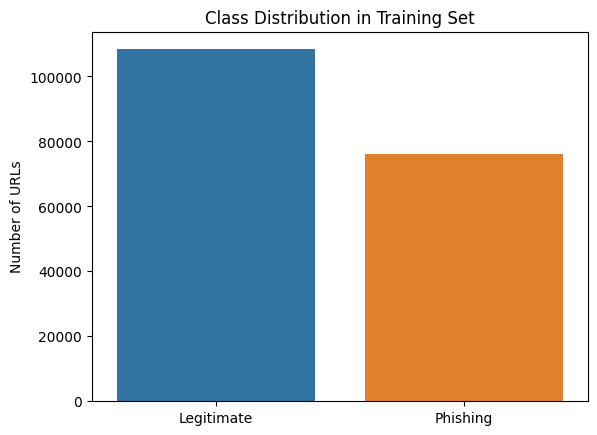

In [51]:
#check for class distributions (helps to explain metrics)
class_summary = (
    train_df["class"]
    .value_counts()
    .to_frame("Count")
)

class_summary["Percentage"] = (
    train_df["class"]
    .value_counts(normalize=True)
    .mul(100)
)

display(class_summary.round(2))

sns.countplot(
    data=train_df,
    x="class",
    order=["Legitimate", "Phishing"],
    hue = 'class'
)

plt.title("Class Distribution in Training Set")
plt.xlabel("")
plt.ylabel("Number of URLs")
plt.show()

The training set contains 184,412 URLs, of which 108,350 (58.75%) are legitimate and 76,062 (41.25%) are phishing. A moderate class imbalance towards legitimate URLs is present, but the dataset is not severely imbalanced. The class distribution should still be considered when interpreting model evaluation metrics, particularly precision, recall and F1-score.

## Exploring  Structural Components of URL

In [52]:
#parse URL into modifiable components
def parse_url(url):
    # Add a temporary scheme only if required for parsing
    parseable_url = url if "://" in url else "http://" + url

    try:
        result = urlsplit(parseable_url)

        return pd.Series({
            "scheme": result.scheme.lower(),
            "hostname": result.hostname or "",
            "path": result.path or "",
            "query": result.query or "",
            "fragment": result.fragment or "",
            "port": result.port
        })

    except (ValueError, TypeError):
        return pd.Series({
            "scheme": "",
            "hostname": "",
            "path": "",
            "query": "",
            "fragment": "",
            "port": np.nan
        })

components = train_df["URL"].apply(parse_url)
train_df = pd.concat([train_df, components], axis=1)

#check for parsing success
print(
    "URLs without a parsed hostname:",
    train_df["hostname"].eq("").sum()
)

display(
    train_df.loc[
        train_df["hostname"].eq(""),
        ["URL", "label"]
    ].head(10)
)

URLs without a parsed hostname: 408


,URL,label
401,43.134.167.94/servicelogin?passive=1209600&amp...,0
1093,google.com/url?q=https://ipfs.io/ipfs/qmpovsve...,0
1205,43.128.92.128/servicelogin?passive=1209600&amp...,0
1725,cloud.mymailwall.com/n/url?l=okcgntugaaaaaa&am...,0
2530,43.156.0.130/servicelogin?passive=1209600&amp;...,0
5703,43.134.191.197/v3/signin/identifier?dsh=s-1106...,0
6118,login.verifyyahoomail.com/login.php?https://lo...,0
8780,43.128.92.128/interactivelogin?continue=https:...,0
9052,43.130.2.171/v3/signin/identifier?dsh=s-738038...,0
9408,login.login.login.blog.verifyyahoomail.com/log...,0


Since the project investigates adversarial manipulation of URLs, each URL is decomposed into its structural components using Python's urlsplit(). The extracted components include the scheme, hostname, path, query, fragment and port. It lets us analyse which parts of a URL differ between phishing and legitimate samples and to define realistic constraints on adversarial modifications.

In [53]:
#decompose hostname

extractor = tldextract.TLDExtract(suffix_list_urls=())

def domain_components(hostname):
    extracted = extractor(hostname)

    registered_domain = ".".join(
        part for part in [
            extracted.domain,
            extracted.suffix
        ]
        if part
    )

    return pd.Series({
        "subdomain": extracted.subdomain,
        "registered_domain": registered_domain,
        "tld": extracted.suffix
    })

domain_parts = train_df["hostname"].apply(domain_components)
train_df = pd.concat([train_df, domain_parts], axis=1)

display(
    train_df[
        [
            "URL",
            "hostname",
            "subdomain",
            "registered_domain",
            "tld"
        ]
    ].head(10)
)

,URL,hostname,subdomain,registered_domain,tld
0,southbankmosaics.com,southbankmosaics.com,,southbankmosaics.com,com
2,voicefmradio.co.uk,voicefmradio.co.uk,,voicefmradio.co.uk,co.uk
3,sfnmjournal.com,sfnmjournal.com,,sfnmjournal.com,com
4,rewildingargentina.org,rewildingargentina.org,,rewildingargentina.org,org
5,globalreporting.org,globalreporting.org,,globalreporting.org,org
6,saffronart.com,saffronart.com,,saffronart.com,com
7,nerdscandy.com,nerdscandy.com,,nerdscandy.com,com
8,hyderabadonline.in,hyderabadonline.in,,hyderabadonline.in,in
9,aap.org,aap.org,,aap.org,org
10,religionenlibertad.com,religionenlibertad.com,,religionenlibertad.com,com


Hostname is further decomposed into its domain components using the tldextract library. Each hostname is separated into its subdomain, registered domain, and top-level domain (TLD)

In [54]:
#URL level features for eda
train_df["url_length"] = train_df["URL"].str.len()
train_df["hostname_length"] = train_df["hostname"].str.len()
train_df["subdomain_length"] = train_df["subdomain"].str.len()
train_df["path_length"] = train_df["path"].str.len()
train_df["query_length"] = train_df["query"].str.len()
train_df["fragment_length"] = train_df["fragment"].str.len()

train_df["letter_count"] = train_df["URL"].str.count(r"[A-Za-z]")
train_df["digit_count"] = train_df["URL"].str.count(r"\d")

train_df["special_count"] = train_df["URL"].apply(
    lambda url: sum(not char.isalnum() for char in url)
)

train_df["letter_ratio"] = (
    train_df["letter_count"] /
    train_df["url_length"].clip(lower=1)
)

train_df["digit_ratio"] = (
    train_df["digit_count"] /
    train_df["url_length"].clip(lower=1)
)

train_df["special_ratio"] = (
    train_df["special_count"] /
    train_df["url_length"].clip(lower=1)
)

train_df["subdomain_count"] = train_df["subdomain"].apply(
    lambda value: 0 if value == "" else len(value.split("."))
)

train_df["path_depth"] = train_df["path"].apply(
    lambda value: len([
        part for part in value.split("/")
        if part
    ])
)

train_df["query_parameter_count"] = train_df["query"].apply(
    lambda value: 0 if value == "" else value.count("&") + 1
)

After decomposing each URL into its structural components, length, character composition and structural complexity are derived to examine differences between phishing and legitimate URLs.

Length-based features are calculated for the complete URL, hostname, subdomain, path, query and fragment. Character composition is represented using the number of alphabetic characters, digits and special characters in each URL. These counts are also normalised by URL length to obtain letter, digit and special-character ratios. Additional structural features are extracted (number of subdomains, path depth and number of query parameters).

In [55]:
numeric_features = [
    "url_length",
    "hostname_length",
    "subdomain_length",
    "path_length",
    "query_length",
    "fragment_length",
    "subdomain_count",
    "path_depth",
    "query_parameter_count",
    "letter_ratio",
    "digit_ratio",
    "special_ratio"
]

summary = (
    train_df
    .groupby("class")[numeric_features]
    .agg(["mean", "median", "std"])
    .round(3).T
)

display(summary)

#choose max sequence length for biLSTM and CNN
percentiles = (
    train_df
    .groupby("class")["url_length"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
)

percentiles.columns = [
    "50th", "75th", "90th", "95th", "99th"
]

display(percentiles)

class                         Legitimate  Phishing
url_length            mean        15.236    37.410
                      median      15.000    24.000
                      std          4.814    65.362
hostname_length       mean        15.236    22.417
                      median      15.000    19.000
                      std          4.814    13.044
subdomain_length      mean         0.175     9.184
                      median       0.000     3.000
                      std          1.196    13.281
path_length           mean         0.000     9.013
                      median       0.000     0.000
                      std          0.000    36.562
query_length          mean         0.000     5.531
                      median       0.000     0.000
                      std          0.000    40.161
fragment_length       mean         0.000     0.375
                      median       0.000     0.000
                      std          0.000    30.525
subdomain_count       mean         0.031     0.687
                      median       0.000     1.000
                      std          0.182     0.804
path_depth            mean         0.000     0.626
                      median       0.000     0.000
                      std          0.000     1.314
query_parameter_count mean         0.000     0.149
                      median       0.000     0.000
                      std          0.000     0.883
letter_ratio          mean         0.907     0.819
                      median       0.923     0.857
                      std          0.051     0.128
digit_ratio           mean         0.004     0.075
                      median       0.000     0.000
                      std          0.029     0.119
special_ratio         mean         0.089     0.107
                      median       0.077     0.102
                      std          0.040     0.042

,50th,75th,90th,95th,99th
class,,,,,
Legitimate,15.0,18.0,22.0,24.0,28.0
Phishing,24.0,40.0,74.0,94.0,220.0


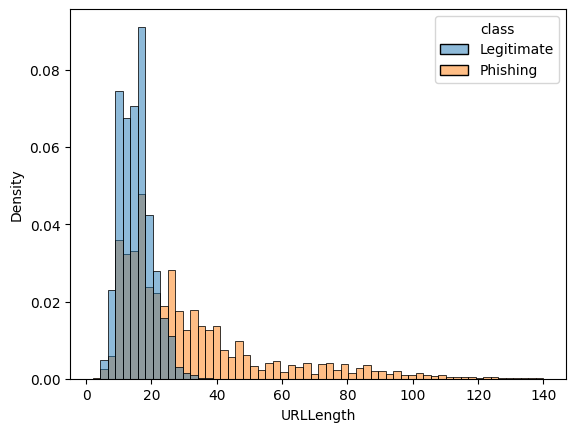

In [56]:
# distribution of URL lengths
sns.histplot(
    data=train_df[train_df.URLLength <= train_df.URLLength.quantile(.99)],
    x="URLLength",
    hue="class",
    bins=60,
    stat="density",
    common_norm=False
)

plt.show()

TLDR Phising url are longer than legitimate url.

Legitimate URLs are relatively short and concentrated, with 95% containing no more than 36 characters and 99% no more than 40. In contrast, phishing URLs exhibit a considerably longer right tail, with the 90th, 95th and 99th percentiles reaching 82, 102 and 230 characters, respectively.

A possible trade-off might happen when selecting the model input length. A very short maximum sequence length would truncate a substantial proportion of phishing URLs and potentially discard useful character-level information, whereas  extreme URLs would increase computational and memory requirements through additional padding. These help us to select an appropriate maximum sequence length.

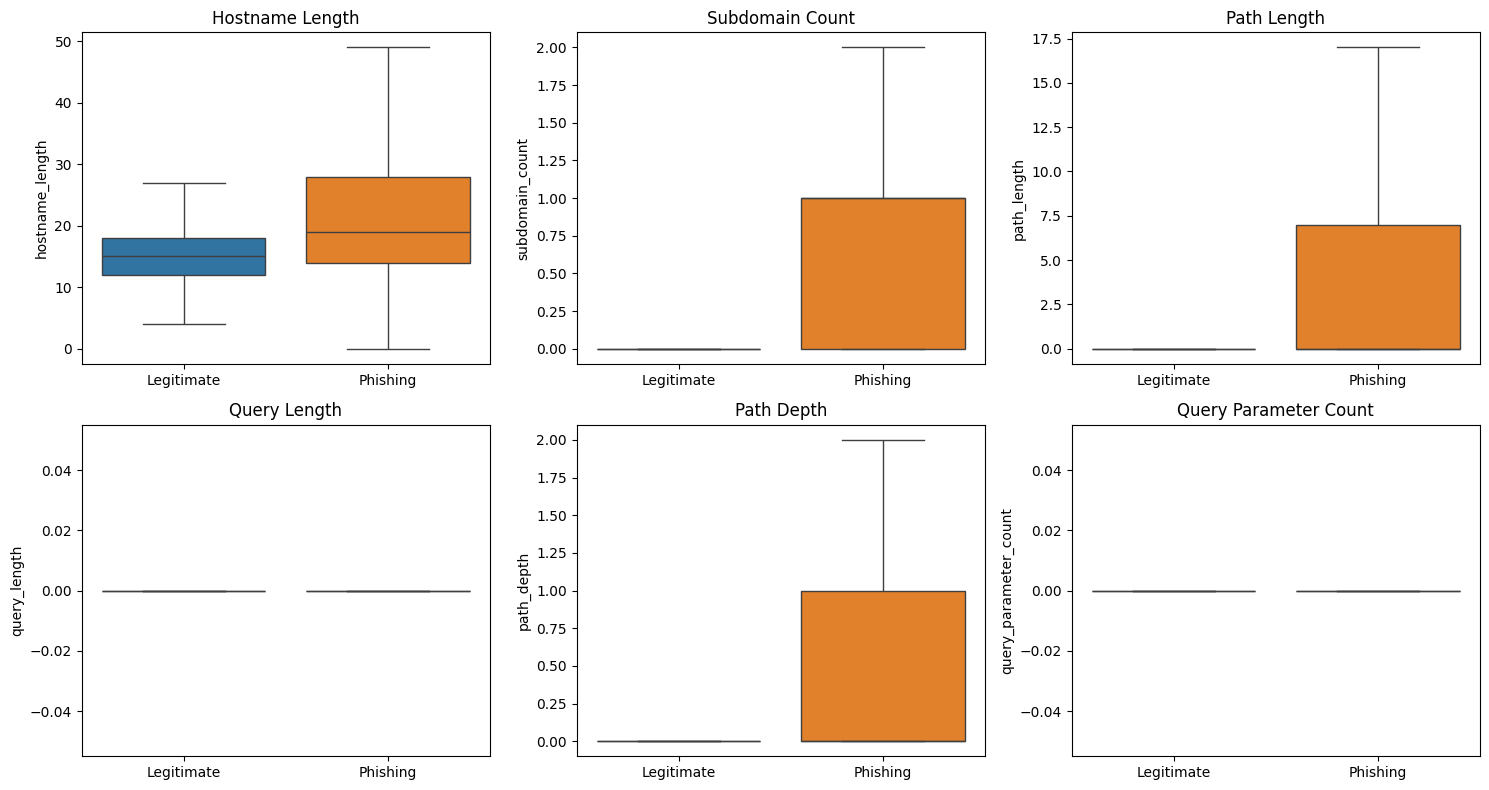

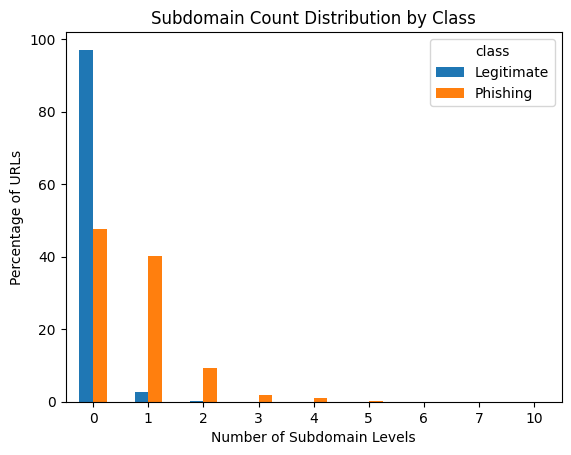

In [57]:
#compare url components 
component_features = [
    "hostname_length",
    "subdomain_count",
    "path_length",
    "query_length",
    "path_depth",
    "query_parameter_count"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, component_features):
    sns.boxplot(
        data=train_df,
        x="class",
        y=feature,
        order=["Legitimate", "Phishing"],
        showfliers=False,
        ax=ax,
        hue='class'
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

subdomain_dist = (
    pd.crosstab(
        train_df["subdomain_count"],
        train_df["class"],
        normalize="columns"
    ) * 100
)

subdomain_dist.plot(kind="bar")

plt.xlabel("Number of Subdomain Levels")
plt.ylabel("Percentage of URLs")
plt.title("Subdomain Count Distribution by Class")
plt.xticks(rotation=0)
plt.show()

Approximately 97.1% of legitimate URLs contain exactly one subdomain level, compared with 64.0% of phishing URLs. Phishing URLs have considerably greater structural variation: 16.1% contain no subdomain, while approximately 19.9% contain two or more subdomain levels, compared with only about 2.9% of legitimate URLs. Phishing URLs in this dataset have more heterogeneous subdomain structures, even though the median subdomain count is one for both classes

## Exploring Character Patterns in URL

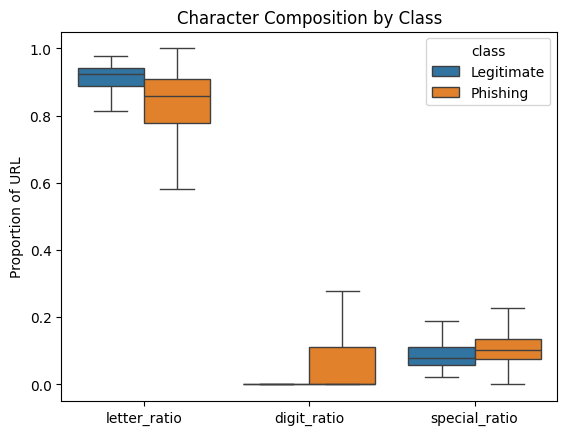

In [58]:
#character patterns (can refine furthur at the digit ratio)
ratio_features = [
    "letter_ratio",
    "digit_ratio",
    "special_ratio"
]

ratio_long = train_df.melt(
    id_vars="class",
    value_vars=ratio_features,
    var_name="character_type",
    value_name="ratio"
)

sns.boxplot(
    data=ratio_long,
    x="character_type",
    y="ratio",
    hue="class",
    showfliers=False
)

plt.title("Character Composition by Class")
plt.xlabel("")
plt.ylabel("Proportion of URL")
plt.show()

Differences in character composition between the two classes. Legitimate URLs generally contain a slightly higher proportion of alphabetic characters, while phishing URLs exhibit substantially greater variation in their digit ratio. In particular, many legitimate URLs contain few or no numerical digits, whereas a larger proportion of phishing URLs contain digits. The special-character ratio also differs between the classes, although the distributions overlap considerably.

## Character Vocabulary and Input Length

In [59]:
#character vocab
from collections import Counter

character_counts = Counter(
    "".join(train_df["URL"])
)

character_table = pd.DataFrame(
    character_counts.items(),
    columns=["character", "frequency"]
).sort_values("frequency", ascending=False)

print("Vocabulary size:", len(character_table))

character_table["display_character"] = (
    character_table["character"]
    .replace({
        " ": "<SPACE>",
        "\t": "<TAB>",
        "\n": "<NEWLINE>"
    })
)
character_table = character_table[
    ["character", "display_character", "frequency"]
]

display(character_table.head(50))

Vocabulary size: 65


,character,display_character,frequency
1,o,o,321902
14,e,e,317712
6,a,a,292260
12,.,.,275446
11,c,c,252029
10,i,i,236355
16,r,r,206681
0,s,s,205140
9,m,m,204546
7,n,n,194615


In [60]:
# determine min frequency threshold of characters to keep 
thresholds = [1, 2, 5, 10, 20, 50, 100]

total = sum(character_counts.values())

for t in thresholds:
    kept_chars = [c for c, n in character_counts.items() if n >= t]
    kept_count = sum(character_counts[c] for c in kept_chars)

    print(
        f"min_freq={t:3d}: "
        f"{len(kept_chars):3d} chars, "
        f"{kept_count/total:.4%} coverage"
    )

min_freq=  1:  65 chars, 100.0000% coverage
min_freq=  2:  61 chars, 99.9999% coverage
min_freq=  5:  58 chars, 99.9998% coverage
min_freq= 10:  58 chars, 99.9998% coverage
min_freq= 20:  56 chars, 99.9989% coverage
min_freq= 50:  53 chars, 99.9963% coverage
min_freq=100:  50 chars, 99.9903% coverage


Set the minimum character frequency to 5, which reduces the number of rare characters (avoid learning unstable embeddings) while retaining 99.9999% of all character occurrences in the training set. 

In [61]:
MIN_CHAR_FREQ = 5
vocab_chars = sorted(c for c, n in character_counts.items() if n >= MIN_CHAR_FREQ)
index_to_string = ["<PAD>", "<UNK>"] + vocab_chars # add <PAD> and <UNK> to vocab
string_to_index = {c: i for i, c in enumerate(index_to_string)}

total = sum(character_counts.values())
kept = sum(character_counts[c] for c in vocab_chars)
print(f"Vocab size: {len(index_to_string)} (kept {len(vocab_chars)} of {len(character_counts)} characters)")

Vocab size: 60 (kept 58 of 65 characters)


In [62]:
# set max length of URL --> pad or truncate URLs for the character-level models
p99 = int(train_df["url_length"].quantile(.99))
max_len = int(np.ceil(p99 / 16) * 16)
print(f"\nMAX_LEN (99 percentile) = {max_len}")

for max_len in [176, 192, 224, 256, 320]:
    truncated = (
        (train_df["url_length"] > max_len)
        .groupby(train_df["class"])
        .mean()
    )
    
    print(f"\nMAX_LEN = {max_len}")
    print(truncated)


MAX_LEN (99 percentile) = 144

MAX_LEN = 176
class
Legitimate    0.000000
Phishing      0.016513
Name: url_length, dtype: float64

MAX_LEN = 192
class
Legitimate    0.000000
Phishing      0.013975
Name: url_length, dtype: float64

MAX_LEN = 224
class
Legitimate    0.000000
Phishing      0.009663
Name: url_length, dtype: float64

MAX_LEN = 256
class
Legitimate    0.000000
Phishing      0.007454
Name: url_length, dtype: float64

MAX_LEN = 320
class
Legitimate    0.000000
Phishing      0.005325
Name: url_length, dtype: float64


Select MAX_LEN = 256 which keeps truncation of phishing URLs below 1%

In [63]:
max_len = 256

# EDA for adversarial attack

### Mutable length for adversarial attack

In [64]:
#caculating mutable length for adverserial attacks
train_df["mutable_length"] = (
    train_df["subdomain_length"]
    + train_df["path_length"]
    + train_df["query_length"]
    + train_df["fragment_length"]
)

train_df["has_mutable_region"] = (
    train_df["mutable_length"] > 0
)

phishing_train = train_df[
    train_df["label"] == 0
].copy()

print(
    "Phishing URLs with at least one mutable character:",
    f"{phishing_train['has_mutable_region'].mean():.2%}"
)

display(
    phishing_train["mutable_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Phishing URLs with at least one mutable character: 66.22%


count    76062.000000
mean        24.103153
std         65.526056
min          0.000000
25%          0.000000
50%         11.000000
75%         28.000000
90%         64.000000
95%         81.000000
99%        211.000000
max       6078.000000
Name: mutable_length, dtype: float64

Availability of Mutable URL Regions:
To assess whether the phishing URLs contain sufficient content for the proposed adversarial attacks, the length of the mutable portion of each URL was calculated. The mutable region was defined as the combined length of the subdomain, path, query and fragment, excluding components such as the registered domain and TLD that are intended to remain unchanged under the attack constraints.

Among phishing URLs in the training set, 95.85% contain at least one character within the defined mutable regions, indicating that the proposed constrained adversarial attacks can be applied to the vast majority of phishing samples. The median mutable length is 11 characters, while 75% of phishing URLs have at most 28 mutable characters. The distribution is strongly right-skewed, with the 90th, 95th and 99th percentiles reaching 64, 81 and 208 characters, respectively.

These results indicate that most phishing URLs provide a non-empty attack surface while the amount of mutable content varies considerably across samples. URLs with no mutable characters cannot be modified under the current threat model and should therefore be treated separately when evaluating adversarial robustness.

### Attack budget selection

Fixed character-edit budgets of k={1,3,5,7} were evaluated relative to phishing URL length. A budget of k=3 corresponds to approximately 9.09% of the median URL and at most 15% of URL characters for 95% of phishing samples. In comparison, k=5 and k=7 correspond to median perturbation rates of 15.15% and 21.21%, respectively, with substantially larger perturbations among shorter URLs. Therefore, k=3 is selected as the primary attack budget, while k=1,5,7 are retained for sensitivity analysis to evaluate model robustness under weaker and stronger adversarial constraints.

In [65]:
#see how edit budget affect URL length...
budgets = [1, 3, 5, 7]

for k in budgets:
    phishing_train[f"relative_budget_{k}"] = (
        k / phishing_train["url_length"] * 100
    )

budget_columns = [
    f"relative_budget_{k}" for k in budgets
]

budget_long = phishing_train.melt(
    value_vars=budget_columns,
    var_name="budget",
    value_name="percentage_of_url"
)

budget_long["budget"] = (
    budget_long["budget"]
    .str.extract(r"(\d+)")
    .astype(int)
)

budget_summary = (
    budget_long
    .groupby("budget")["percentage_of_url"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)

display(budget_summary)

,count,mean,std,min,25%,50%,75%,90%,95%,max
budget,,,,,,,,,,
1,76062.0,4.70,3.01,0.02,2.5,4.17,6.25,9.09,10.0,50.0
3,76062.0,14.11,9.02,0.05,7.5,12.50,18.75,27.27,30.0,150.0
5,76062.0,23.52,15.04,0.08,12.5,20.83,31.25,45.45,50.0,250.0
7,76062.0,32.93,21.06,0.11,17.5,29.17,43.75,63.64,70.0,350.0


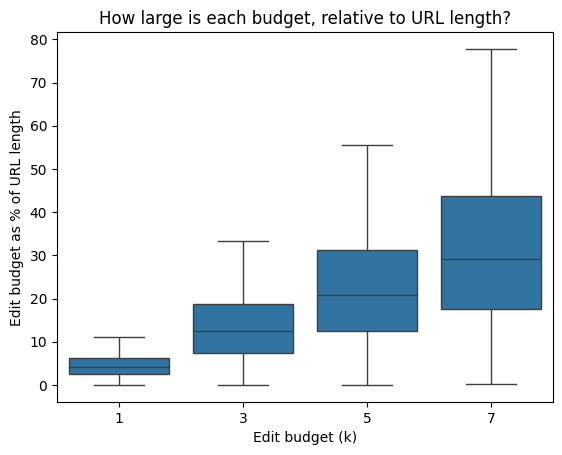

In [66]:
sns.boxplot(
    data=budget_long,
    x="budget",
    y="percentage_of_url",
    showfliers=False
)

plt.ylabel("Edit budget as % of URL length")
plt.xlabel("Edit budget (k)")
plt.title("How large is each budget, relative to URL length?")

plt.show()

Choose edit budget (k) = 3 --> justify
k=3 (median 8.73%) Keep perturbations small relative to the original URL while giving the attack meaningful room to operate. k=1 (median 2.91%) is too small to test robustness meaningfully; k=5 and k=7 push toward approx 15–20% of URL length and risk no longer being subtle perturbations.

In [67]:
edit_budget = 3

# Save datasets

In [68]:
## run this again when all params + eda are finalised to get dataset
final_cols = ["URL", "label", "split"]
df_final = df[final_cols].copy()

os.makedirs("data", exist_ok=True)
for s in ["train", "val", "test"]:
    df_final[df_final["split"] == s].drop(columns="split").to_csv(f"data/{s}.csv", index=False)

with open("data/vocab.json", "w") as f:
    json.dump({"index_to_string": index_to_string, "pad_idx": 0, "unk_idx": 1}, f, indent=1)
with open("data/config.json", "w") as f:
    json.dump({"max_len": max_len, "vocab_size": len(index_to_string), "budget": edit_budget,
               "positive_class": "phishing (label 0)"}, f, indent=1)

print(df_final["split"].value_counts())

split
train    184412
test      25165
val       22170
Name: count, dtype: int64
